<center><h1>Практическое задание</h1></center>
 
1. Выбрать набор данных для детекции объектов
2. Попробовать различные архитектуры модели, как и разные backbone, так и SSD
3. Сделать наложение реальных и предсказанных объектов одновременно, отделив их различными цветами
4. Замерить IoU на малой выборке изображений

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.utils import draw_bounding_boxes
from PIL import Image
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision.models.detection import retinanet_resnet50_fpn_v2, ssdlite320_mobilenet_v3_large
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.models.detection.ssdlite import SSDLiteHead
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from ultralytics import YOLO
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from tqdm import tqdm
from torchvision.ops import batched_nms
import numpy as np
from functools import partial
from torch.optim.lr_scheduler import StepLR

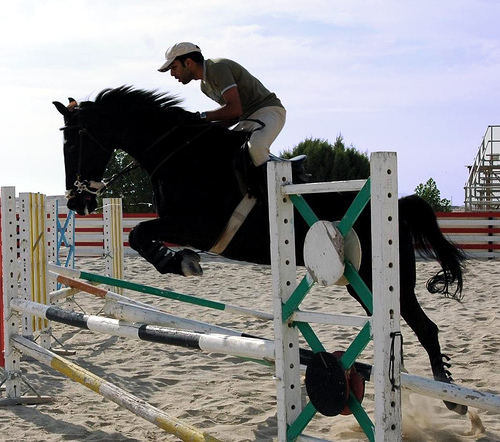

In [2]:
dataset = datasets.VOCDetection(root='./SimpleNN', image_set='train', download=False)
dataset[0][0]

In [3]:
dataset[0][1]

{'annotation': {'folder': 'VOC2012',
  'filename': '2008_000008.jpg',
  'source': {'database': 'The VOC2008 Database',
   'annotation': 'PASCAL VOC2008',
   'image': 'flickr'},
  'size': {'width': '500', 'height': '442', 'depth': '3'},
  'segmented': '0',
  'object': [{'name': 'horse',
    'pose': 'Left',
    'truncated': '0',
    'occluded': '1',
    'bndbox': {'xmin': '53', 'ymin': '87', 'xmax': '471', 'ymax': '420'},
    'difficult': '0'},
   {'name': 'person',
    'pose': 'Unspecified',
    'truncated': '1',
    'occluded': '0',
    'bndbox': {'xmin': '158', 'ymin': '44', 'xmax': '289', 'ymax': '167'},
    'difficult': '0'}]}}

In [4]:
names = []
for sample in dataset:
    names.extend(obj['name'] for obj in sample[1]['annotation']['object'])

names = sorted(list(set(names)))
print(names)



['aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']


In [5]:
# full_names = ['background'] + names

# tar2idx = {name: idx for idx, name in enumerate(full_names)}
# idx2tar = {idx: name for idx, name in enumerate(full_names)}

full_names = ['background'] + names
tar2idx = {name: idx for idx, name in enumerate(full_names)}
idx2tar = {idx: name for idx, name in enumerate(full_names)}


print(tar2idx)
print(idx2tar)

{'background': 0, 'aeroplane': 1, 'bicycle': 2, 'bird': 3, 'boat': 4, 'bottle': 5, 'bus': 6, 'car': 7, 'cat': 8, 'chair': 9, 'cow': 10, 'diningtable': 11, 'dog': 12, 'horse': 13, 'motorbike': 14, 'person': 15, 'pottedplant': 16, 'sheep': 17, 'sofa': 18, 'train': 19, 'tvmonitor': 20}
{0: 'background', 1: 'aeroplane', 2: 'bicycle', 3: 'bird', 4: 'boat', 5: 'bottle', 6: 'bus', 7: 'car', 8: 'cat', 9: 'chair', 10: 'cow', 11: 'diningtable', 12: 'dog', 13: 'horse', 14: 'motorbike', 15: 'person', 16: 'pottedplant', 17: 'sheep', 18: 'sofa', 19: 'train', 20: 'tvmonitor'}


In [6]:
def target_transform(targets):
    target = {}
    target['boxes'] = torch.tensor([[
        float(x['bndbox']['xmin']),
        float(x['bndbox']['ymin']),
        float(x['bndbox']['xmax']),
        float(x['bndbox']['ymax'])
    ] for x in targets['annotation']['object']], dtype=torch.float32)
    target['labels'] = torch.tensor([tar2idx[x['name']] for x in targets['annotation']['object']], dtype=torch.int64)
    return target

In [7]:
def show(images):
    to_pil = transforms.ToPILImage()
    if not isinstance(images, list):
        images = [images]
    fig, axes = plt.subplots(ncols=len(images), squeeze=False, figsize=(20, 10))
    for idx, image in enumerate(images):
        image = image.detach()
        image = to_pil(image)
        axes[0, idx].imshow(np.asarray(image))
        axes[0, idx].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

def draw_single_image(image, boxes, labels, color):
    colours = [color for _ in boxes]
    show(draw_bounding_boxes(image, boxes, labels, colors=colours, width=6))

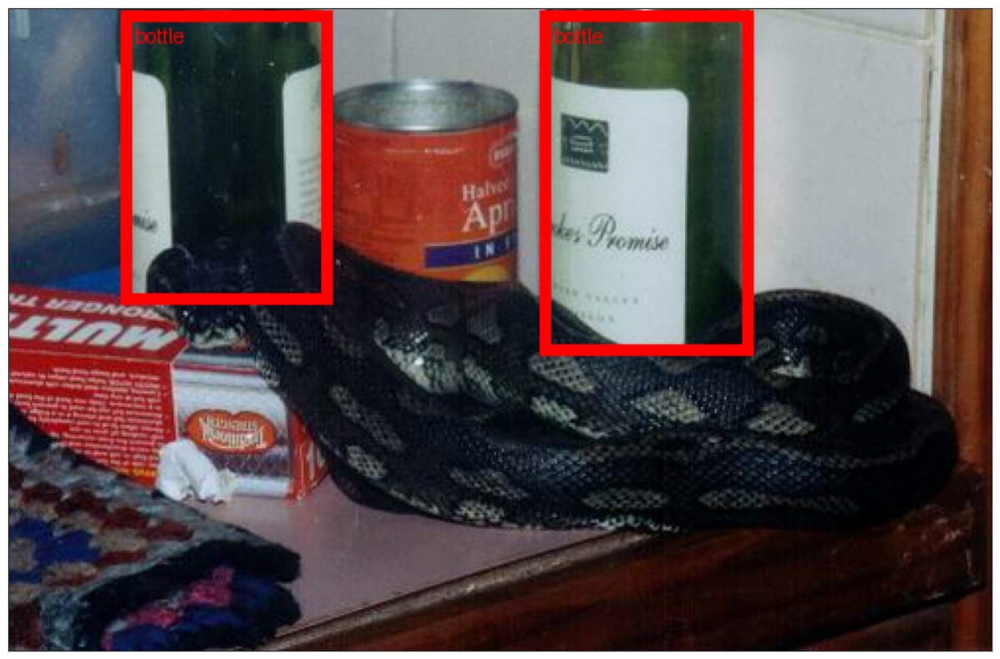

In [8]:
draw_single_image(transforms.PILToTensor()(dataset[1][0]), target_transform(dataset[1][1])['boxes'],
                  [idx2tar[label.item()] for label in target_transform(dataset[1][1])['labels']], 'red')

In [9]:
def collate_fn(batch):
    return tuple(zip(*batch))

train_data = datasets.VOCDetection(root='./SimpleNN', image_set='train',
                                   transform=transforms.ToTensor(),
                                   target_transform=target_transform)

valid_data = datasets.VOCDetection(root='./SimpleNN', image_set='val',
                                   transform=transforms.ToTensor(),
                                   target_transform=target_transform)

train_loader = DataLoader(train_data, batch_size=6, shuffle=True, pin_memory=True,
                          collate_fn=collate_fn)

valid_loader = DataLoader(valid_data, batch_size=6, shuffle=False, pin_memory=True,
                          collate_fn=collate_fn)

In [10]:
model_retina = retinanet_resnet50_fpn_v2(weights="DEFAULT")
model_retina

RetinaNet(
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      

In [11]:
in_channels = model_retina.head.classification_head.conv[0][0].in_channels
num_anchors = model_retina.head.classification_head.num_anchors

print("In channels: %d\nNum anchors: %d\n" % (in_channels, num_anchors))

model_retina.head.classification_head = RetinaNetClassificationHead(
    in_channels=in_channels,
    num_anchors=num_anchors,
    num_classes=len(names) + 1,
    norm_layer=partial(torch.nn.GroupNorm, 32)
)

# saved_weights = torch.load('retinanet_resnet50_fpn_v2_tuned.pth')
# model_retina.load_state_dict(saved_weights, strict=False)

model_retina

In channels: 256
Num anchors: 9



RetinaNet(
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      

In [12]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

device


'cuda:0'

In [13]:
params = sum([p.numel() for p in model_retina.parameters()])

for param in model_retina.parameters():
    param.requires_grad = False

for param in model_retina.head.classification_head.parameters():
    param.requires_grad = True

for param in model_retina.head.regression_head.parameters():
    param.requires_grad = True

tune_params = sum([p.numel() for p in model_retina.parameters() if p.requires_grad])

print("Count parameters for retina model: %d\nCount need to tuning parameters: %d\n" % (params, tune_params), end="")

Count parameters for retina model: 36746785
Count need to tuning parameters: 5241313


In [14]:
MAP = MeanAveragePrecision()

optimizer = torch.optim.Adam([p for p in model_retina.parameters() if p.requires_grad], lr=1e-4)

In [15]:
def train_model_steplr(
    model, 
    train_loader,
    valid_loader,
    criterion, 
    device='cuda:0',
    optimizer=None, 
    num_epochs=10, 
    step_size_lr=10, 
    gamma_lr=0.1
):
    epochs_loss = [0] * num_epochs
    epochs_map = [0] * num_epochs
    if (optimizer is None):
        optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)
    scheduler = StepLR(optimizer=optimizer, step_size=step_size_lr, gamma=gamma_lr)

    model.to(device)
    criterion.to(device)
    for epoch in range(num_epochs):
        model = model.train()
        for data, targets in tqdm(train_loader, desc='TRAIN'):
            data = list(_.to(device).float() for _ in data)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            y_pred = model(data, targets)
            loss = sum(value for value in y_pred.values())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epochs_loss[epoch] += loss.item()
        epochs_loss[epoch] /= len(train_loader)
        print(f'EPOCH {(epoch+1):2d}: Loss: {epochs_loss[epoch]:.2f}')

        model = model.eval()
        criterion.reset()
        with torch.inference_mode():
            for data, targets in tqdm(valid_loader, desc="VAL"):
                data = list(_.to(device).float() for _ in data)
                targets = [{k: v.to(device) for k, v in t.items()} for t in targets] 
                y_pred = model(data)
                criterion.update(y_pred, targets)
        epochs_map[epoch] = criterion.compute()['map']
        scheduler.step()
        print(f'EPOCH {(epoch+1):2d}: MAP: {epochs_map[epoch]:.2f}')
    return model, epochs_map, epochs_loss

In [16]:
model_retina.transform.min_size = (600,)
model_retina.transform.max_size = 1000
model_retina, map_retina, loss_retina = train_model_steplr(model_retina, train_loader, valid_loader, criterion=MAP,
                                  device=device, optimizer=optimizer, num_epochs=5,
                                  step_size_lr=10, gamma_lr=0.1)

TRAIN: 100%|██████████| 953/953 [16:17<00:00,  1.03s/it]


EPOCH  1: Loss: 0.50


VAL:   0%|          | 1/971 [00:00<07:51,  2.06it/s]d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)
VAL: 100%|██████████| 971/971 [10:06<00:00,  1.60it/s]


EPOCH  1: MAP: 0.50


TRAIN: 100%|██████████| 953/953 [16:40<00:00,  1.05s/it]


...

EPOCH  4: MAP: 0.55


TRAIN: 100%|██████████| 953/953 [16:42<00:00,  1.05s/it]


EPOCH  5: Loss: 0.31


VAL: 100%|██████████| 971/971 [10:11<00:00,  1.59it/s]


EPOCH  5: MAP: 0.56


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_training_results(epochs_loss, epochs_map):
    epochs = list(range(1, len(epochs_loss) + 1))
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    axes[0].bar(epochs, epochs_loss, color="#C800FF", alpha=0.4, label='Loss per Epoch')
    axes[0].plot(epochs, epochs_loss, color="#1F7CC0", linewidth=2.5, marker='o', 
                 markersize=8, markeredgecolor='white', markeredgewidth=1.5, label='Loss Trend')
    
    axes[0].set_title('Training Loss Progression', fontsize=14, fontweight='bold', pad=15)
    axes[0].set_xlabel('Epochs', fontsize=12)
    axes[0].set_ylabel('Loss Value', fontsize=12)
    axes[0].set_xticks(epochs)
    axes[0].legend(frameon=True, facecolor='white', edgecolor='none')
    
    for x, y in zip(epochs, epochs_loss):
        axes[0].text(x, y + (max(epochs_loss) * 0.02), f'{y:.3f}', ha='center', va='bottom', fontsize=9, color='#333333')

    axes[1].bar(epochs, epochs_map, color="#C800FF", alpha=0.4, label='mAP per Epoch')
    axes[1].plot(epochs, epochs_map, color="#1F7CC0", linewidth=2.5, marker='s', 
                 markersize=8, markeredgecolor='white', markeredgewidth=1.5, label='mAP Trend')
    
    axes[1].set_title('Validation mAP (Mean Average Precision)', fontsize=14, fontweight='bold', pad=15)
    axes[1].set_xlabel('Epochs', fontsize=12)
    axes[1].set_ylabel('mAP Value', fontsize=12)
    axes[1].set_ylim(0, 1.05)
    axes[1].set_xticks(epochs)
    axes[1].legend(frameon=True, facecolor='white', edgecolor='none')

    for x, y in zip(epochs, epochs_map):
        axes[1].text(x, y + 0.02, f'{y:.3f}', ha='center', va='bottom', fontsize=9, color='#333333')

    plt.tight_layout()
    plt.show()


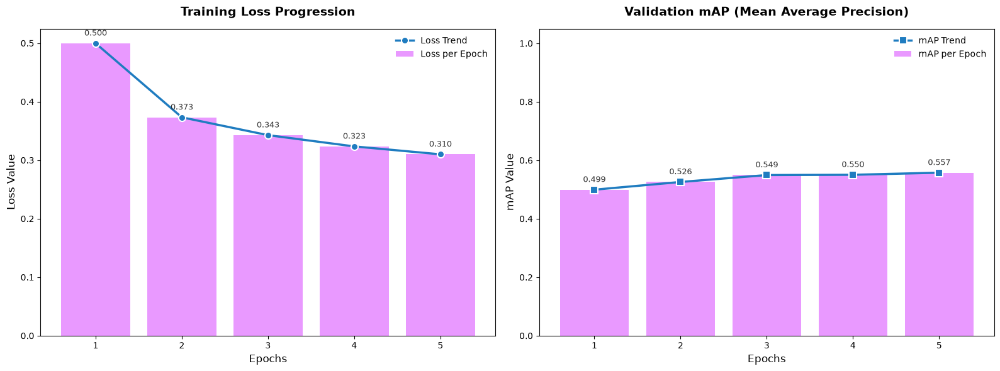

In [18]:
plot_training_results(loss_retina, map_retina)

<h1><center>Prior fine-tuning retina_net</h1></center>

![Снимок экрана 2026-07-05 185309.png](<attachment:Снимок экрана 2026-07-05 185309.png>)
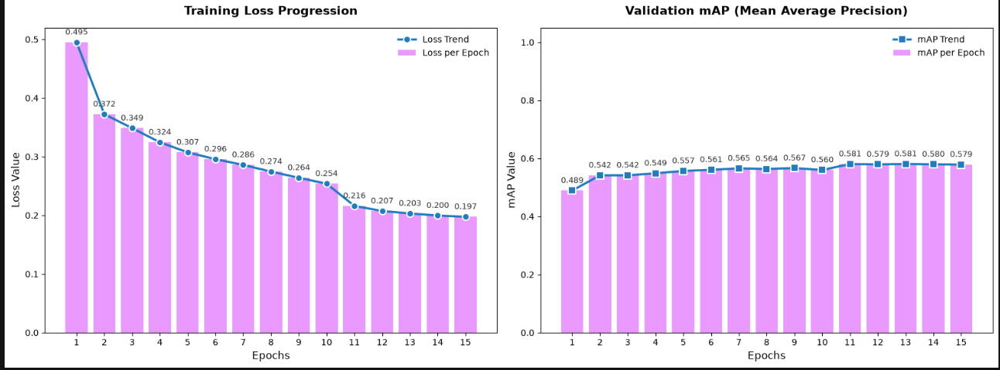

In [19]:
torch.save(model_retina.state_dict(), 'retinanet_resnet50_fpn_v2_tuned_weights.pth')
torch.save(model_retina, 'retinanet_resnet50_fpn_v2_tuned.pth')

In [ ]:
def filter_predictions(orig_prediction, score_thresh=0.3, iou_thresh=0.2):
    keep_scores = orig_prediction['scores'] > score_thresh
    
    boxes = orig_prediction['boxes'][keep_scores]
    scores = orig_prediction['scores'][keep_scores]
    labels = orig_prediction['labels'][keep_scores]

    keep_nms = batched_nms(boxes, scores, labels, iou_thresh)

    final_prediction = {
        'boxes': boxes[keep_nms],
        'scores': scores[keep_nms],
        'labels': labels[keep_nms]
    }
    
    return final_prediction

@torch.inference_mode()
def vizualize(model, batch, score_thresh=0.5, iou_thresh=0.4):
    model.eval()
    to_pil = transforms.ToPILImage()
    
    xs, ys = batch
    for i, (x, y) in enumerate(zip(xs, ys)):
        pred = model([x.to(device).float()])[0]
        pred = {k: v.cpu() for k, v in pred.items()}
        
        pred = filter_predictions(pred, score_thresh=score_thresh, iou_thresh=iou_thresh)
        
        img_uint8 = (x.cpu() * 255).to(torch.uint8)
        
        true_labels = [idx2tar[label.item()] for label in y['labels']]
        final_image = draw_bounding_boxes(img_uint8, boxes=y['boxes'], 
                                         labels=true_labels, 
                                         width=3, colors='red')
        
        if len(pred['boxes']) > 0:
            pred_labels = [idx2tar[label.item()] for label in pred['labels']]
            final_image = draw_bounding_boxes(final_image, boxes=pred['boxes'], 
                                                  labels=pred_labels, 
                                                  width=3, colors='blue')
            
        fig = plt.figure(figsize=(16, 8), facecolor='white')
        ax = fig.gca()
        
        ax.imshow(to_pil(final_image))
        ax.axis('off')
        
        ax.set_title(f'Target (Red) and Predicted (Blue) boxes ({score_thresh}:{iou_thresh})')
        plt.show()
        
        if (i >= 9): break

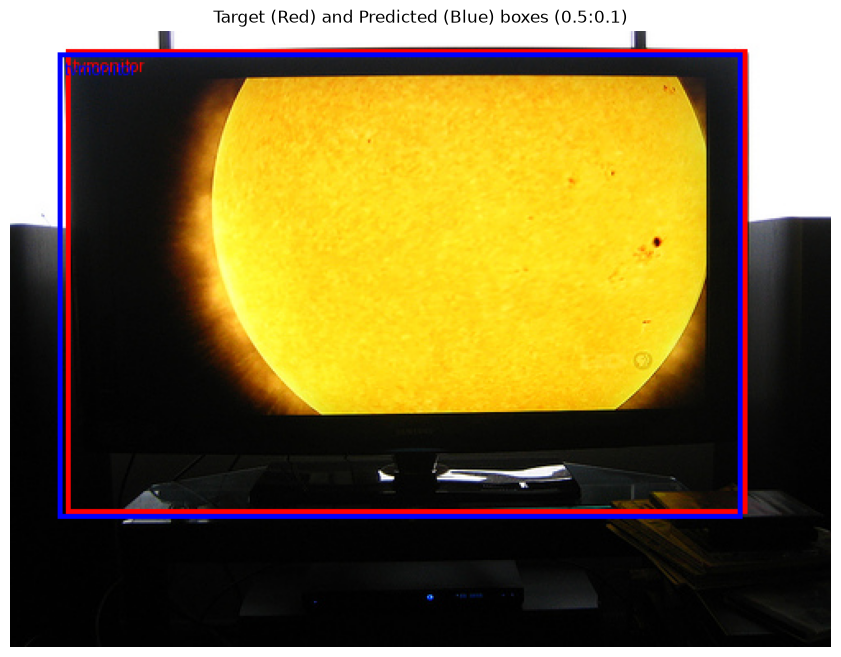

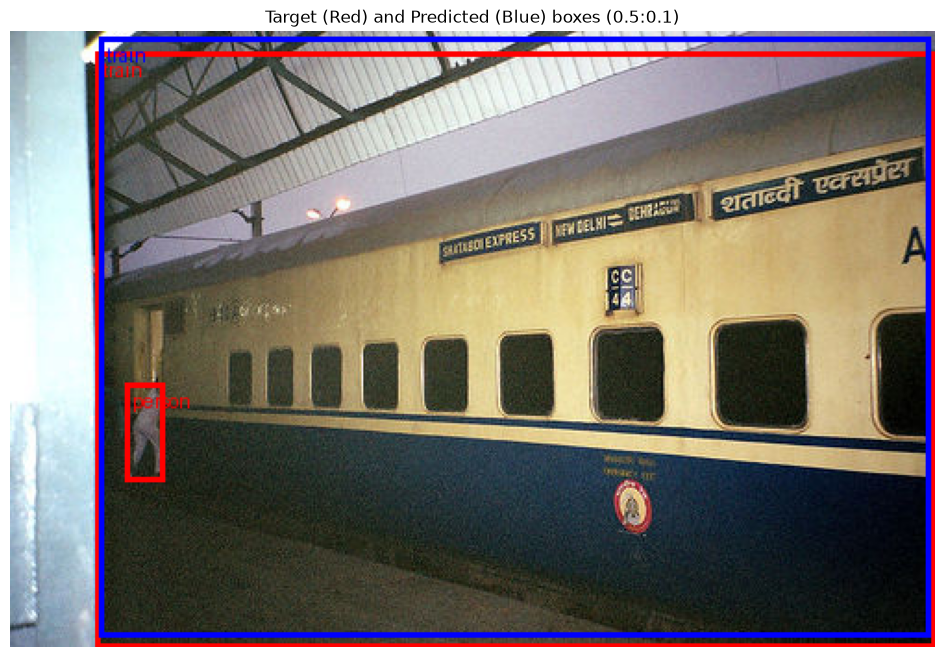

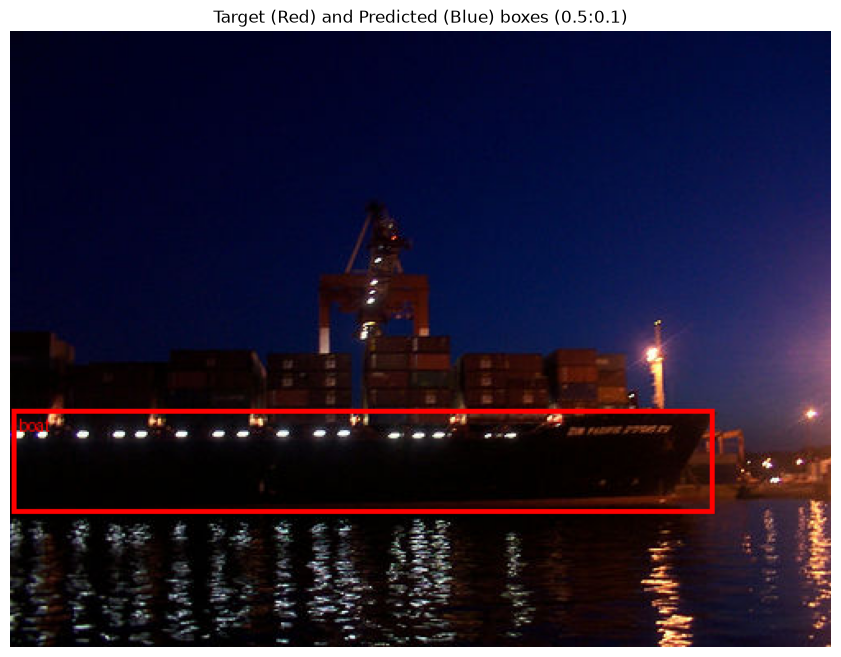

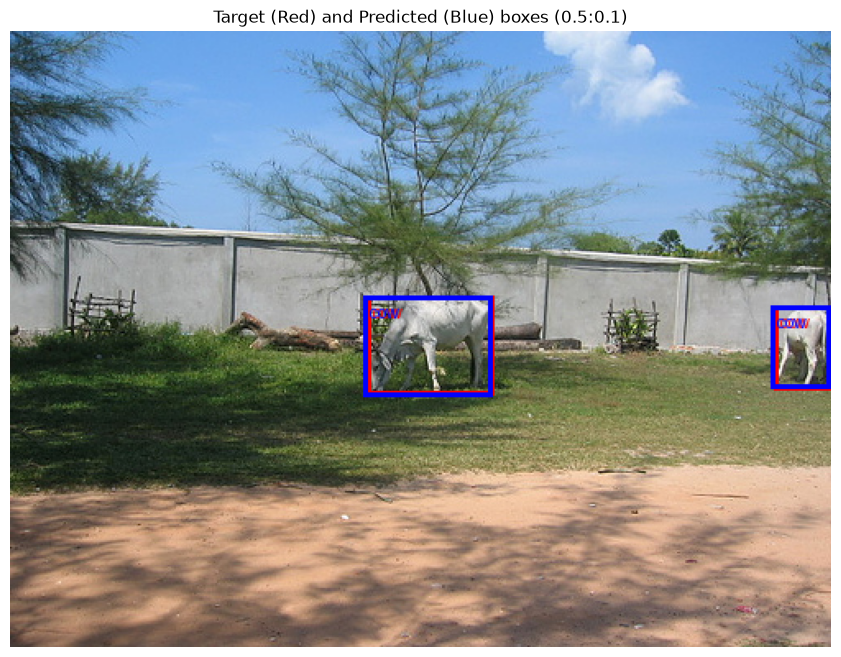

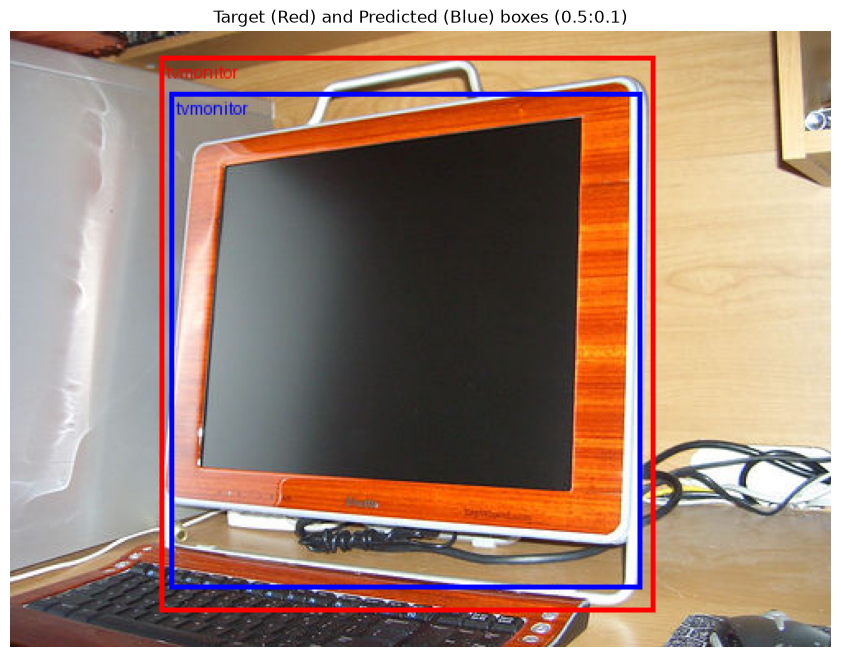

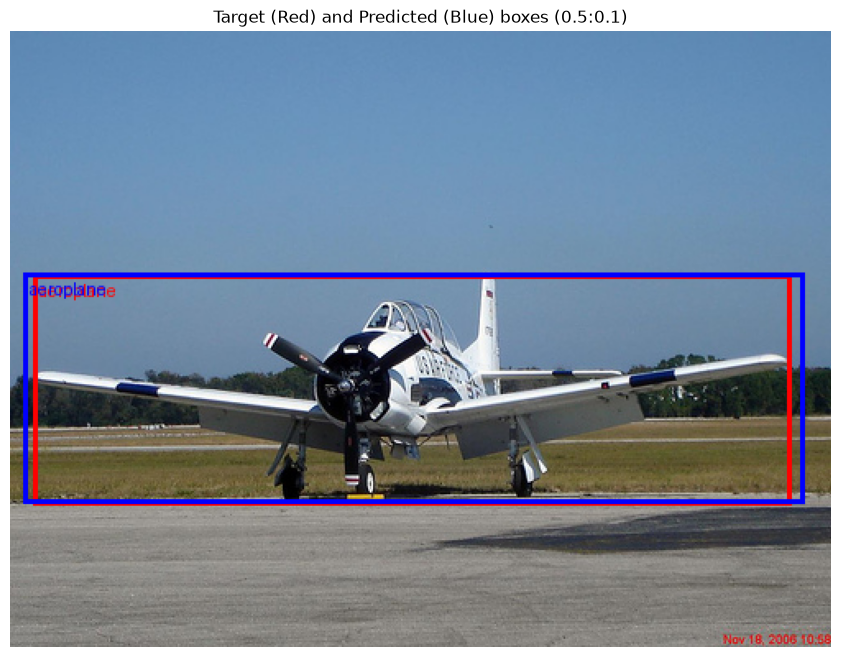

In [31]:
dataiter = iter(valid_loader)
data, targets = next(dataiter)
model_retina.to(device)

vizualize(model_retina, (data, targets), score_thresh=0.5, iou_thresh=0.1)

<h2>Дообучение ssdlite320

In [ ]:
if 'model_retina' in locals():
    del model_retina

if 'model_ssdlite320' in locals():
    del model_ssdlite320

torch.cuda.empty_cache()

In [35]:
model_ssdlite320 = ssdlite320_mobilenet_v3_large(weights="DEFAULT")
print(model_ssdlite320)

params = sum(p.numel() for p in model_ssdlite320.parameters())

print("Number of params original ssdlite320: ", params)


in_channels = [layer[0][0].in_channels for layer in model_ssdlite320.head.classification_head.module_list]
num_anchors = model_ssdlite320.anchor_generator.num_anchors_per_location()

print(f'In channels: {in_channels}\nNum anchors: {num_anchors}\n')

model_ssdlite320.head = SSDLiteHead(
    in_channels = in_channels,
    num_anchors = num_anchors,
    num_classes = len(names) + 1,
    norm_layer = partial(torch.nn.BatchNorm2d, eps=0.001, momentum=0.03)
)

saved_weights = torch.load('ssdlite320_mobilenet_v3_large_self.pth')
model_ssdlite320.load_state_dict(saved_weights, strict=False)

model_ssdlite320

SSD(
  (backbone): SSDLiteFeatureExtractorMobileNet(
    (features): Sequential(
      (0): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (2): Hardswish()
        )
        (1): InvertedResidual(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
              (1): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
              (2): ReLU(inplace=True)
            )
            (1): Conv2dNormActivation(
              (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (1): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
            )
          )
        )
        (2): Invert

SSD(
  (backbone): SSDLiteFeatureExtractorMobileNet(
    (features): Sequential(
      (0): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (2): Hardswish()
        )
        (1): InvertedResidual(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
              (1): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
              (2): ReLU(inplace=True)
            )
            (1): Conv2dNormActivation(
              (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (1): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
            )
          )
        )
        (2): Invert

In [22]:
for param in model_ssdlite320.parameters():
    param.requires_grad = False

for param in model_ssdlite320.head.parameters():
    param.requires_grad = True

tune_params = sum(p.numel() for p in model_ssdlite320.parameters() if p.requires_grad)

print(f'Tune parameters of ssdlite320: {tune_params}')

Tune parameters of ssdlite320: 397188


In [23]:
MAP = MeanAveragePrecision()

optimizer = torch.optim.Adam([p for p in model_ssdlite320.parameters() if p.requires_grad], lr=1e-4)


In [ ]:
def train_model_steplr_ssdlite(
    model, 
    train_loader,
    valid_loader,
    criterion, 
    device='cuda:0',
    optimizer=None, 
    num_epochs=10, 
    step_size_lr=10, 
    gamma_lr=0.1,
    start_epoch_train_all=5
):
    epochs_loss = [0] * num_epochs
    epochs_map = [0] * num_epochs
    if (optimizer is None):
        optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)
    scheduler = StepLR(optimizer=optimizer, step_size=step_size_lr, gamma=gamma_lr)

    model.to(device)
    criterion.to(device)
    for epoch in range(num_epochs):
        if ((epoch + 1) == start_epoch_train_all):
            for param in model.parameters():
                param.requires_grad = True
            current_lr = scheduler.get_last_lr()[0] 
            optimizer = torch.optim.Adam(model.parameters(), lr=current_lr)
            scheduler.optimizer = optimizer

        model = model.train()
        for data, targets in tqdm(train_loader, desc='TRAIN'):
            data = list(_.to(device).float() for _ in data)
            targets = [{
                'boxes': t['boxes'].to(device).float(),
                'labels': t['labels'].to(device).long(),
            } for t in targets]
            y_pred = model(data, targets)
            loss = sum(value for value in y_pred.values())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epochs_loss[epoch] += loss.item()
        epochs_loss[epoch] /= len(train_loader)
        print(f'EPOCH {(epoch+1):2d}: Loss: {epochs_loss[epoch]:.2f}')

        model = model.eval()
        criterion.reset()
        with torch.inference_mode():
            for data, targets in tqdm(valid_loader, desc="VAL"):
                data = list(_.to(device).float() for _ in data)
                y_pred = model(data)
                y_pred = [{k: v.cpu() for k, v in t.items()} for t in y_pred]
                # targets = [{k: v.to(device).long() for k, v in t.items()} for t in targets] 
                # y_pred = model(data)
                # preds = [{k: v.detach().cpu() for k, v in p.items()} for p in preds]
                # gts = [{'boxes': t['boxes'].cpu(), 'labels': t['labels'].cpu()} for t in targets]
                criterion.update(y_pred, targets)
        epochs_map[epoch] = criterion.compute()['map']
        scheduler.step()
        print(f'EPOCH {(epoch+1):2d}: MAP: {epochs_map[epoch]:.2f}')
    return model, epochs_map, epochs_loss

In [25]:
train_loader = DataLoader(train_data, batch_size=16, shuffle=True, pin_memory=True,
                          collate_fn=collate_fn)

valid_loader = DataLoader(valid_data, batch_size=16, shuffle=False, pin_memory=True,
                          collate_fn=collate_fn)

In [30]:
model_ssdlite320, map_ssdlite320, loss_ssdlite320 = train_model_steplr_ssdlite(model_ssdlite320, train_loader, valid_loader, criterion=MAP,
                                  device=device, optimizer=optimizer, num_epochs=15,
                                  step_size_lr=10, gamma_lr=0.1, start_epoch_train_all=5)


TRAIN: 100%|██████████| 358/358 [00:51<00:00,  6.89it/s]


EPOCH  1: Loss: 10.89


VAL:   0%|          | 0/364 [00:00<?, ?it/s]d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)
VAL: 100%|██████████| 364/364 [01:26<00:00,  4.23it/s]


EPOCH  1: MAP: 0.10


TRAIN: 100%|██████████| 358/358 [00:51<00:00,  6.91it/s]


...

EPOCH 14: MAP: 0.39


TRAIN: 100%|██████████| 358/358 [01:16<00:00,  4.66it/s]


EPOCH 15: Loss: 1.79


VAL: 100%|██████████| 364/364 [01:20<00:00,  4.52it/s]


EPOCH 15: MAP: 0.39


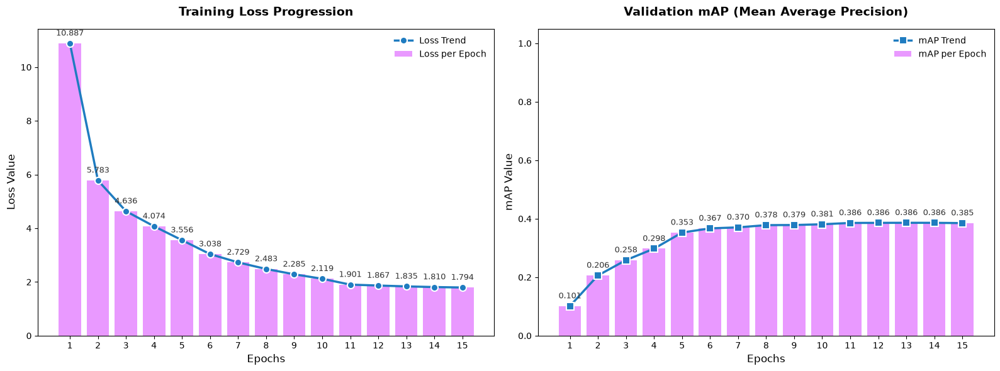

In [31]:
plot_training_results(loss_ssdlite320, map_ssdlite320)

In [ ]:
# torch.save(model_ssdlite320.state_dict(), 'ssdlite320_mobilenet_v3_large_self_state_dict.pth')
# torch.save(model_ssdlite320.state_dict(), 'ssdlite320_mobilenet_v3_large_self.pth')

NameError: name 'model_ssdlite320' is not defined

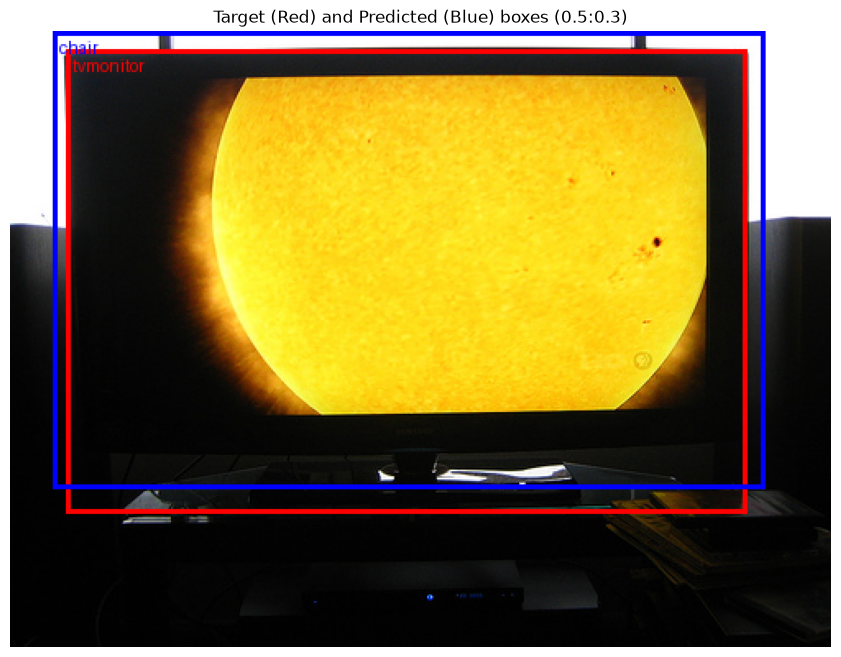

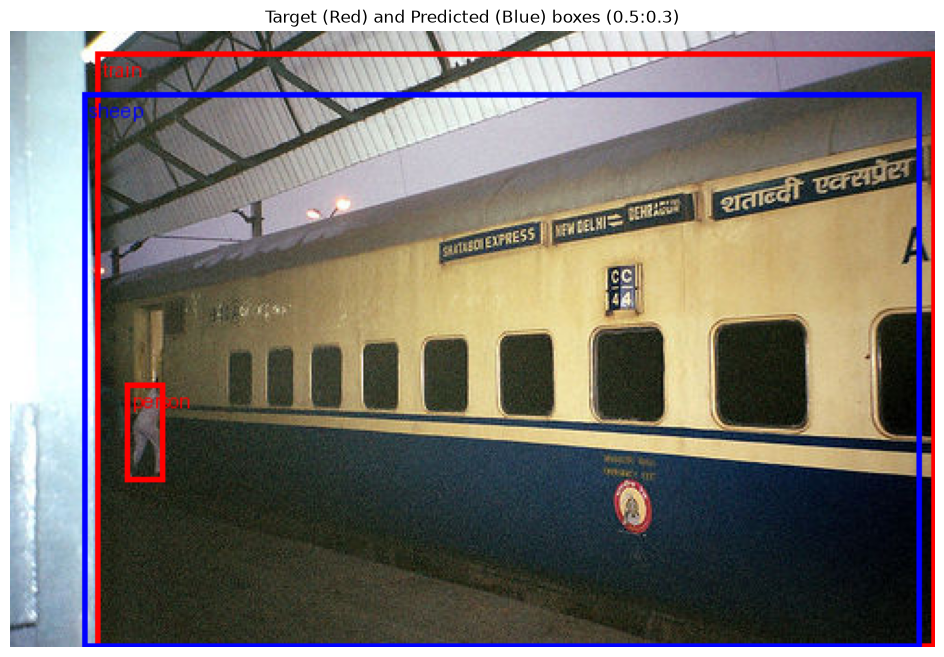

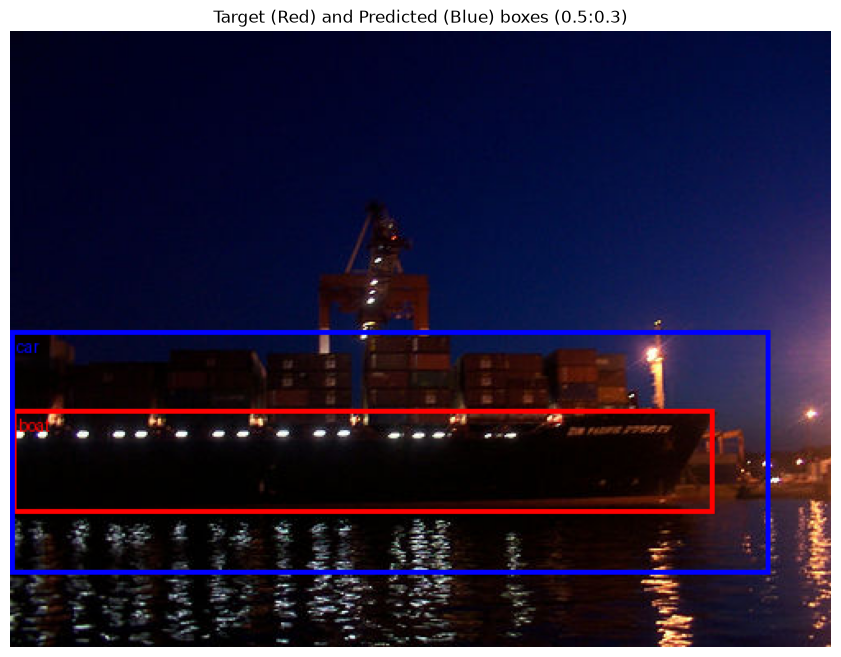

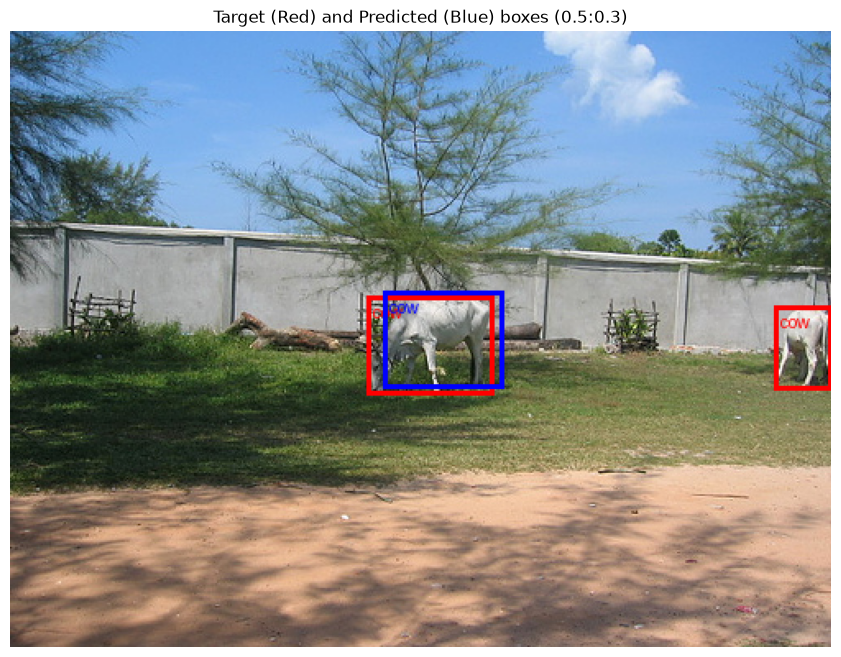

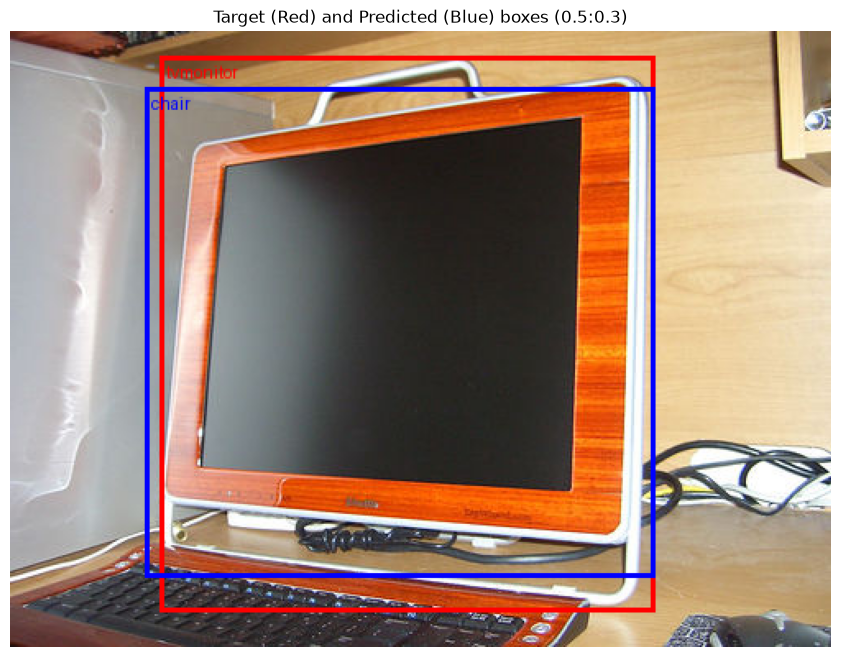

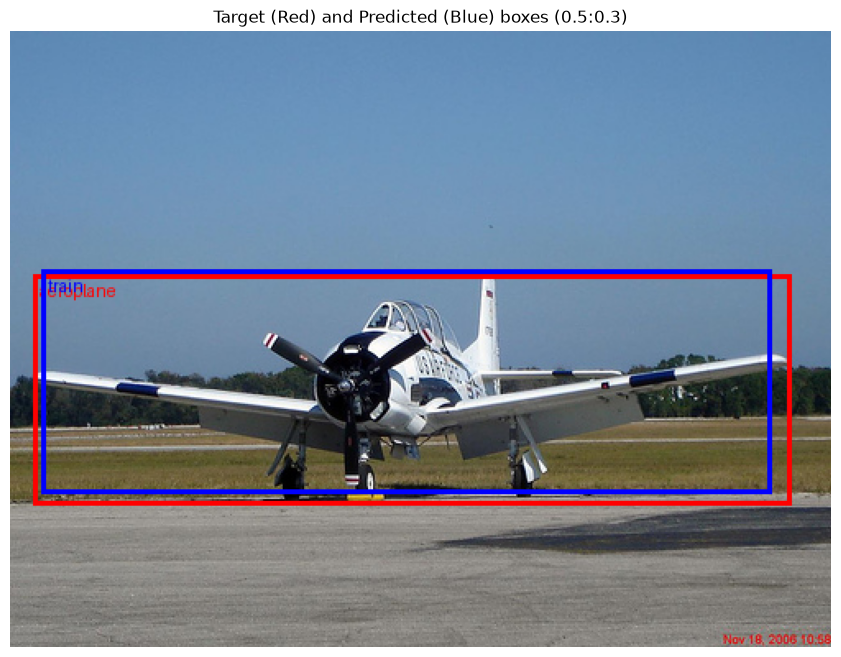

In [37]:
dataiter = iter(valid_loader)
data, targets = next(dataiter)
model_ssdlite320.to(device)

vizualize(model_ssdlite320, (data, targets), score_thresh=0.5, iou_thresh=0.3)